# Сравнение инструментов обработки NYC Yellow Taxi

## Введение

**Датасет:** [NYC Yellow Taxi](https://www.kaggle.com/datasets/elemento/nyc-yellow-taxi-trip-data),
январь 2015 и январь–март 2016.

**Задача:** группировка по трём полям `cell_lat × cell_lon × hour`;
количество поездок, средний тариф и суммарная дистанция. Гео-ячейка приблизительно 1 × 1 км;
`hour` — час суток (0–23), не дата-час. Это профиль спроса для планирования смен.
Профиль используется для подготовки прогноза спроса к 06:00; целевой эффект — сократить холостые машино-часы на 25 %.

Сравниваем Pandas, Dask и Spark, анализируем физический план и skew,
проверяем оптимизации независимо. Дополнительно сравниваем Polars и DuckDB на CPU.
Таблицы и графики получены полным запуском ноутбука. Текстовые выводы описывают сохранённый прогон;
после повторного запуска их нужно сверить с новыми измерениями.

## Часть 1: Подготовка окружения и данных

### 1.1. Окружение

Из корня проекта: `uv venv --python 3.13`, `uv pip install -r requirements.txt`.
Для Spark нужен JDK 17 и `JAVA_HOME` (см. README). Выберите `.venv` как ядро ноутбука.
Полный запуск проводит три повтора каждого замера и может занять десятки минут.

In [1]:
import os

from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

SOURCE = Path(os.environ.get("TAXI_SOURCE", ROOT / "data/parquet"))

DATA = ROOT / "data"

# Промежуточные файлы нужны только для обмена с дочерними процессами и Spark.
import tempfile
workspace = None if os.environ.get("BENCH_WORK") else tempfile.TemporaryDirectory(prefix="taxi-benchmark-")
ARTIFACTS = Path(os.environ["BENCH_WORK"] if workspace is None else workspace.name)

KEYS = ["cell_lat", "cell_lon", "hour"]

COLUMNS = KEYS + ["fare_amount", "trip_distance"]

SIZES = {"100mb": 100_000_000, "1gb": 1_000_000_000}

CORES = int(os.environ.get("LAB_CORES", "4"))

local_java = list((ROOT / ".venv/java").glob("*/Contents/Home"))

if local_java:
    os.environ.setdefault("JAVA_HOME", str(local_java[0]))

def files(size, fmt="parquet"):
    return sorted((DATA / size).glob(f"*.{fmt}"))

def guard_pandas(paths):
    """Ограничение эксперимента, не утверждение о пределе Pandas."""
    import pyarrow.parquet as pq

    logical = sum(pq.ParquetFile(p).metadata.num_rows * 40 for p in paths)
    if logical > 1_000_000_000:
        raise ValueError(f"Pandas: срез {logical:,} байт превышает лимит 1 ГБ")
os.environ.setdefault("POLARS_MAX_THREADS", str(CORES))
os.environ.setdefault("OMP_NUM_THREADS", str(CORES))
os.environ.setdefault("SPARK_LOCAL_IP", "127.0.0.1")

'127.0.0.1'

In [2]:
import os
import sys
import json
import platform
from pathlib import Path
from importlib.metadata import version

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import polars as pl
from IPython.display import display

plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False, 'axes.spines.right': False})
environment = {'platform': platform.platform(), 'python': sys.version, 'cores_used': CORES,
               'packages': {p: version(p) for p in ['pandas', 'dask', 'pyspark', 'polars', 'duckdb', 'great-expectations']}}
display(environment)

{'platform': 'macOS-27.0.1-arm64-arm-64bit-Mach-O',
 'python': '3.13.14 (main, Jun 23 2026, 15:20:43) [Clang 22.1.3 ]',
 'cores_used': 4,
 'packages': {'pandas': '3.1.1',
  'dask': '2026.8.0',
  'pyspark': '4.3.0',
  'polars': '2.1.0',
  'duckdb': '2.0.0',
  'great-expectations': '1.24.1'}}

### 1.2. Загрузка, очистка и размеры

Исходные CSV за январь 2015 и январь–март 2016 помещаем в `data/raw/`.
Функция `pack` унифицирует имена и типы 19 колонок,
добавляет месяц из имени файла и потоково записывает Parquet с компрессией zstd
в `data/parquet/`. Уже упакованные файлы пропускаются. Исходные CSV не изменяются.
Для готового Parquet путь можно переопределить через `TAXI_SOURCE`.
Отбрасываем строки с пропусками, неверными координатами NYC, датой вне месяца выгрузки,
неположительной длительностью/дистанцией, отрицательным или нечисловым тарифом.
Пропуски не заполняем нулями: это сместило бы среднее и профиль спроса.
Полные дубликаты удаляем по исходным полям до получения ключей агрегации.

100 МБ и 1 ГБ — **логический размер пяти фиксированных 8-байтовых полей** (40 байт/строка),
а не размер сжатого Parquet. Показываем оба размера. Срезы вложенные, по порядку месяцев;
это контроль объёма, не случайная репрезентативная выборка. Внутри месяца порядок после unique не гарантирован.
Очистка не включается в время запроса: все движки получают один и тот же результат очистки.

In [3]:
from pathlib import Path

import polars as pl

SCHEMA = {
    "vendor_id": pl.Int8, "pickup_datetime": pl.Datetime("us"), "dropoff_datetime": pl.Datetime("us"),
    "passenger_count": pl.Int8, "trip_distance": pl.Float64,
    "pickup_longitude": pl.Float64, "pickup_latitude": pl.Float64, "rate_code_id": pl.Int8,
    "store_and_fwd_flag": pl.String, "dropoff_longitude": pl.Float64, "dropoff_latitude": pl.Float64,
    "payment_type": pl.Int8, "fare_amount": pl.Float64, "extra": pl.Float64, "mta_tax": pl.Float64,
    "tip_amount": pl.Float64, "tolls_amount": pl.Float64, "improvement_surcharge": pl.Float64,
    "total_amount": pl.Float64,
}

MONTHS = ("2015-01", "2016-01", "2016-02", "2016-03")

def scan_csv(path: Path) -> pl.LazyFrame:
    return (pl.scan_csv(path, with_column_names=lambda _: list(SCHEMA), schema_overrides=SCHEMA)
            .with_columns(month=pl.lit(path.stem[-7:])))

def pack(raw_dir: Path, output: Path = SOURCE):
    paths = [raw_dir / f"yellow_tripdata_{month}.csv" for month in MONTHS]
    missing = [str(path) for path in paths if not path.is_file()]
    if missing:
        raise FileNotFoundError("Не найдены CSV: " + ", ".join(missing))
    output.mkdir(parents=True, exist_ok=True)
    for path in paths:
        target = output / f"{path.stem}.parquet"
        if not target.exists():
            scan_csv(path).sink_parquet(target, compression="zstd")
        print(f"{target.name}: {target.stat().st_size / 1e6:.1f} МБ")

In [4]:
def prepare():
    sources = sorted(SOURCE.glob("yellow_tripdata_*.parquet"))
    if not sources:
        raise FileNotFoundError(f"Нет исходных Parquet в {SOURCE}. См. README.md")
    DATA.mkdir(exist_ok=True)
    ARTIFACTS.mkdir(exist_ok=True)
    full = DATA / "full"
    full.mkdir(exist_ok=True)
    stats = []
    for path in sources:
        raw = pl.scan_parquet(path)
        valid = raw.filter(
            pl.col("pickup_latitude").is_between(40.49, 40.92)
            & pl.col("pickup_longitude").is_between(-74.27, -73.68)
            & (pl.col("pickup_datetime").dt.strftime("%Y-%m") == path.stem[-7:])
            & (pl.col("dropoff_datetime") > pl.col("pickup_datetime"))
            & pl.col("fare_amount").is_finite() & (pl.col("fare_amount") >= 0)
            & pl.col("trip_distance").is_finite() & (pl.col("trip_distance") > 0)
        ).drop_nulls()
        # Полные дубликаты удаляем ДО проекции: разные поездки могут дать одинаковые признаки.
        clean = valid.unique()
        counts = [q.select(pl.len()).collect().item() for q in (raw, valid, clean)]
        stats.append(dict(file=path.name, raw=counts[0], invalid=counts[0]-counts[1],
                          duplicates=counts[1]-counts[2], clean=counts[2]))
        clean.select(
            (pl.col("pickup_latitude") / 0.01).floor().cast(pl.Int64).alias("cell_lat"),
            (pl.col("pickup_longitude") / 0.012).floor().cast(pl.Int64).alias("cell_lon"),
            pl.col("pickup_datetime").dt.hour().cast(pl.Int64).alias("hour"),
            pl.col("fare_amount").cast(pl.Float64), pl.col("trip_distance").cast(pl.Float64),
        ).sink_parquet(full / path.name, compression="zstd", row_group_size=250_000)
    # Месяцы не пересекаются после проверки даты: дедупликации внутри месяца достаточно.
    # Строка = 3 int64 + 2 float64 = 40 байт. Размер среза — логический, НЕ сжатый.
    import pyarrow as pa
    import pyarrow.parquet as pq

    manifest = []
    for size, target in SIZES.items():
        folder = DATA / size
        folder.mkdir(exist_ok=True)
        remaining = target // 40
        for i, path in enumerate(sorted(full.glob("*.parquet"))):
            batches = []
            for batch in pq.ParquetFile(path).iter_batches(batch_size=250_000):
                take = min(remaining, batch.num_rows)
                if take:
                    batches.append(batch.slice(0, take))
                    remaining -= take
                if not remaining:
                    break
            if batches:
                pq.write_table(pa.Table.from_batches(batches), folder / f"part-{i:02}.parquet", compression="zstd")
            if not remaining:
                break
        if remaining:
            raise ValueError(f"Недостаточно очищенных данных для {size}")
    for size in [*SIZES, "full"]:
        paths = sorted((DATA / size).glob("*.parquet"))
        rows = sum(pq.ParquetFile(p).metadata.num_rows for p in paths)
        manifest.append(dict(size=size, rows=rows, logical_mb=rows*40/1e6,
                             disk_mb=sum(p.stat().st_size for p in paths)/1e6))
    return stats, manifest

In [5]:
if not list(SOURCE.glob('yellow_tripdata_*.parquet')):
    pack(ROOT / 'data/raw', SOURCE)

cleaning, datasets = prepare()
display(pd.DataFrame(cleaning))
display(pd.DataFrame(datasets))

,file,raw,invalid,duplicates,clean
0,yellow_tripdata_2015-01.parquet,12748986,311720,0,12437266
1,yellow_tripdata_2016-01.parquet,10906858,227439,0,10679419
2,yellow_tripdata_2016-02.parquet,11382049,237537,0,11144512
3,yellow_tripdata_2016-03.parquet,12210952,245737,0,11965215


,size,rows,logical_mb,disk_mb
0,100mb,2500000,100.00000,9.237694
1,1gb,25000000,1000.00000,86.318275
2,full,46226412,1849.05648,197.866000


### 1.3. Проверка качества Great Expectations

Потоково считаем нарушения по всей очищенной истории. GX проверяет нулевые счётчики; это не проверка только первых N строк.

In [6]:
import great_expectations as gx

def validate():
    """GX проверяет все строки через распределения значений компактной таблицы."""
    import great_expectations as gx

    # Проверки на всем наборе считаем потоково, GX валидирует полученные счетчики.
    q = pl.scan_parquet(DATA / "full/*.parquet")
    checks = q.select(
        nulls=pl.sum_horizontal(pl.all().is_null()).sum(),
        bad_hour=(~pl.col("hour").is_between(0, 23)).sum(),
        bad_fare=((pl.col("fare_amount") < 0) | ~pl.col("fare_amount").is_finite()).sum(),
        bad_distance=((pl.col("trip_distance") <= 0) | ~pl.col("trip_distance").is_finite()).sum(),
    ).collect().to_pandas()
    ctx = gx.get_context(mode="ephemeral")
    batch = (ctx.data_sources.add_pandas("taxi").add_dataframe_asset("quality")
             .add_batch_definition_whole_dataframe("full").get_batch(batch_parameters={"dataframe": checks}))
    suite = ctx.suites.add(gx.ExpectationSuite("clean_data"))
    for column in checks.columns:
        suite.add_expectation(gx.expectations.ExpectColumnValuesToBeBetween(column=column, min_value=0, max_value=0))
    result = batch.validate(suite)
    assert result.success, "Проверка качества не пройдена"
    return checks, result.to_json_dict()

/Users/whyalive/WORK/Магистратура 2 курс/bigdata/bigdata-engine-benchmark/.venv/lib/python3.13/site-packages/pyspark/sql/connect/utils.py:41: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


In [7]:
checks, quality = validate()
display(checks)
display(pd.DataFrame([{'expectation': r['expectation_config']['type'],
                       'column': r['expectation_config']['kwargs']['column'], 'success': r['success']}
                      for r in quality['results']]))
assert quality['success']
try:
    guard_pandas(files('full'))
except ValueError as error:
    print('OK: полный набор заблокирован до чтения:', error)
else:
    raise AssertionError('Ожидался полный набор > 1 ГБ')

Calculating Metrics:   0%|          | 0/31 [00:00<?, ?it/s]

Calculating Metrics:   0%|          | 0/31 [00:00<?, ?it/s]

Calculating Metrics:   6%|▋         | 2/31 [00:00<00:00, 2203.47it/s]

Calculating Metrics:   6%|▋         | 2/31 [00:00<00:00, 1757.88it/s]

Calculating Metrics:  10%|▉         | 3/31 [00:00<00:00, 2316.87it/s]

Calculating Metrics:  10%|▉         | 3/31 [00:00<00:00, 2065.14it/s]

... (5 outputs left out)

Calculating Metrics: 100%|██████████| 31/31 [00:00<00:00, 4945.93it/s]

,nulls,bad_hour,bad_fare,bad_distance
0,0,0,0,0


,expectation,column,success
0,expect_column_values_to_be_between,nulls,True
1,expect_column_values_to_be_between,bad_hour,True
2,expect_column_values_to_be_between,bad_fare,True
3,expect_column_values_to_be_between,bad_distance,True


OK: полный набор заблокирован до чтения: Pandas: срез 1,849,056,480 байт превышает лимит 1 ГБ


**Вывод:** после очистки осталось 46 226 412 поездок; полных дубликатов не обнаружено.
Все четыре проверки GX успешны: пропусков и нарушений ограничений часа, тарифа и дистанции нет.
Полный набор занимает 1849,06 МБ логически и 197,87 МБ в сжатом Parquet;
срезы содержат 2,5 и 25 млн строк. Очистка общая для всех реализаций.

Ограничение Pandas — правило безопасности, а не доказательство неизбежного OOM после 1 ГБ.
Конфигурация Spark: `local[4]` по умолчанию (`LAB_CORES`), driver 3 ГБ,
baseline: shuffle/default parallelism 200, AQE выключен, UTC, event log включён.
Это локальный процесс JVM, а не измерение сетевого кластера.

## Часть 2: Сравнение производительности

### 2.1. Методика и проверка результатов

Каждый замер — новый процесс. Время включает импорт движка, чтение, агрегацию и материализацию,
для Spark также запуск/остановку JVM: сравниваем стоимость **разового задания**, не прогретого SQL-сервиса.
Запись компактного результата на диск выполняется после измерения.
Три повтора, медиана и диапазон; порядок движков меняется. Файловый кэш ОС не сбрасываем.
RSS опрашивается каждые 20 мс по дереву процессов, включая JVM (сумма RSS может повторно учитывать общие страницы).
CPU — сумма user+system; 100 % = одно полностью занятое ядро, допустимо >100 %.
I/O — дисковые счётчики дерева процессов: psutil, а на macOS — libproc через ctypes.
На macOS число операций недоступно (NaN), но байты чтения/записи измеряются.
Попадания в кеш ОС могут дать 0 дисковых байт; это не логический объём прочитанных данных.
Входные и shuffle-байты Spark отдельно доступны из event log.

Результаты всех движков и оптимизаций автоматически сверяются по ключам/count точно,
по среднему и сумме с числовым допуском. Dask работает локальным threaded scheduler с четырьмя потоками,
а не с отдельно поднятым distributed-кластером. Pandas, Polars и DuckDB — оба среза; Spark — также полный набор.

### 2.2. Одинаковая агрегация в четырёх движках

In [8]:
def pandas_query(paths):
    import pandas as pd

    guard_pandas(paths)
    frame = pd.read_parquet(paths)
    return frame.groupby(KEYS, as_index=False).agg(
        trips=("fare_amount", "size"), avg_fare=("fare_amount", "mean"),
        distance=("trip_distance", "sum"))

def dask_query(paths):
    import dask
    import dask.dataframe as dd

    with dask.config.set(scheduler="threads", num_workers=CORES):
        frame = dd.read_parquet([str(p) for p in paths], split_row_groups=True)
        return frame.groupby(KEYS).agg(
            trips=("fare_amount", "count"), avg_fare=("fare_amount", "mean"),
            distance=("trip_distance", "sum")).compute().reset_index()

def polars_query(paths):
    import polars as pl

    return (pl.scan_parquet(paths).group_by(KEYS).agg(
        pl.len().cast(pl.Int64).alias("trips"), pl.col("fare_amount").mean().alias("avg_fare"),
        pl.col("trip_distance").sum().alias("distance"))
        .collect(engine="streaming").to_pandas())

def duckdb_query(paths):
    import duckdb

    with duckdb.connect() as con:
        con.execute(f"SET threads={CORES}")
        con.from_parquet([str(p) for p in paths]).create_view("trips")
        return con.sql("""
            SELECT cell_lat, cell_lon, hour, count(*) AS trips,
                   avg(fare_amount) AS avg_fare, sum(trip_distance) AS distance
            FROM trips GROUP BY cell_lat, cell_lon, hour
        """).df()

ENGINES = {"pandas": pandas_query, "dask": dask_query,
           "polars": polars_query, "duckdb": duckdb_query}

### 2.3. Spark: агрегация и настройки

In [9]:
import contextlib

import io

import json

VARIANTS = {
    "baseline": dict(partitions=200, aqe=False, repartition=False, salt=False),
    "partitions": dict(partitions=CORES*3, aqe=False, repartition=False, salt=False),
    "aqe": dict(partitions=200, aqe=True, repartition=False, salt=False),
    "repartition": dict(partitions=200, aqe=False, repartition=True, salt=False),
    "salt": dict(partitions=200, aqe=False, repartition=False, salt=True),
    "combined": dict(partitions=CORES*3, aqe=True, repartition=False, salt=False),
}

def session(label, options):
    from pyspark.sql import SparkSession

    events = ARTIFACTS / "events" / label
    events.mkdir(parents=True, exist_ok=True)
    return (SparkSession.builder.master(f"local[{CORES}]").appName(label)
            .config("spark.driver.memory", "3g")
            .config("spark.sql.shuffle.partitions", str(options["partitions"]))
            .config("spark.default.parallelism", str(options["partitions"]))
            .config("spark.sql.adaptive.enabled", str(options["aqe"]).lower())
            .config("spark.eventLog.enabled", "true")
            .config("spark.eventLog.compress", "false")
            .config("spark.eventLog.dir", events.as_uri())
            .config("spark.ui.enabled", "false")
            .config("spark.sql.session.timeZone", "UTC").getOrCreate())

def aggregate(frame, options):
    from pyspark.sql import functions as F

    if options["repartition"]:
        frame = frame.repartition(options["partitions"], *KEYS)
    if not options["salt"]:
        return frame.groupBy(*KEYS).agg(F.count("*").alias("trips"),
                                       F.avg("fare_amount").alias("avg_fare"),
                                       F.sum("trip_distance").alias("distance"))
    # Два шага; среднее восстанавливается через SUM/COUNT, а не AVG(AVG).
    salted = frame.withColumn("salt", (F.rand(seed=42)*16).cast("int"))
    partial = salted.groupBy(*KEYS, "salt").agg(
        F.count("*").alias("n"), F.sum("fare_amount").alias("fare_sum"),
        F.sum("trip_distance").alias("distance"))
    return partial.groupBy(*KEYS).agg(F.sum("n").alias("trips"),
        (F.sum("fare_sum")/F.sum("n")).alias("avg_fare"), F.sum("distance").alias("distance"))

def query(paths, label, variant):
    import pandas as pd

    options = VARIANTS[variant]
    spark = session(label, options)
    spark.sparkContext.setLogLevel("ERROR")
    try:
        frame = spark.read.parquet(*[str(p) for p in paths])
        result = aggregate(frame, options)
        plan = io.StringIO()
        with contextlib.redirect_stdout(plan):
            result.explain(mode="formatted")
        # Число ключей ограничено сеткой NYC x 24: collect только компактного результата.
        rows = result.collect()
        with contextlib.redirect_stdout(plan):
            result.explain(mode="formatted")
        (ARTIFACTS / f"plan-{label}.txt").write_text(plan.getvalue())
        (ARTIFACTS / f"config-{label}.json").write_text(json.dumps(dict(spark.sparkContext.getConf().getAll()), indent=2))
        return pd.DataFrame([r.asDict() for r in rows])
    finally:
        spark.stop()

### 2.4. Измерение ресурсов и запуск повторов

In [10]:
import ctypes

import sys

class RusageInfoV2(ctypes.Structure):
    # Порядок полей из macOS SDK: sys/resource.h, rusage_info_v2.
    _fields_ = [("uuid", ctypes.c_uint8 * 16)] + [
        (name, ctypes.c_uint64) for name in (
            "user_time", "system_time", "pkg_idle_wkups", "interrupt_wkups",
            "pageins", "wired_size", "resident_size", "phys_footprint",
            "proc_start_abstime", "proc_exit_abstime", "child_user_time",
            "child_system_time", "child_pkg_idle_wkups", "child_interrupt_wkups",
            "child_pageins", "child_elapsed_abstime", "diskio_bytesread",
            "diskio_byteswritten",
        )
    ]

if sys.platform == "darwin":
    _rusage = ctypes.CDLL("/usr/lib/libproc.dylib", use_errno=True).proc_pid_rusage
    _rusage.argtypes = [ctypes.c_int, ctypes.c_int, ctypes.c_void_p]
    _rusage.restype = ctypes.c_int
else:
    _rusage = None

def counters(process):
    """read_ops, write_ops, read_bytes, write_bytes; None означает недоступность."""
    if hasattr(process, "io_counters"):
        io = process.io_counters()
        return io.read_count, io.write_count, io.read_bytes, io.write_bytes
    if _rusage is not None:
        usage = RusageInfoV2()
        if _rusage(process.pid, 2, ctypes.byref(usage)) == 0:
            return None, None, usage.diskio_bytesread, usage.diskio_byteswritten
    return None, None, None, None

import threading

import time

import psutil

class Monitor:
    def __enter__(self):
        self.process = psutil.Process()
        self.stop = threading.Event()
        self.peak = 0
        self.cpu = {}
        self.io = {}
        self.start = time.perf_counter()
        self.sample()
        self.base_cpu = sum(self.cpu.values())
        self.base_io = self.io_totals()
        self.thread = threading.Thread(target=self.run, daemon=True)
        self.thread.start()
        return self

    def sample(self):
        processes = [self.process, *self.process.children(recursive=True)]
        rss = 0
        for process in processes:
            try:
                rss += process.memory_info().rss
                cpu = process.cpu_times()
                self.cpu[process.pid] = cpu.user + cpu.system
                io = counters(process)
                if any(value is not None for value in io):
                    self.io[process.pid] = io
            except (psutil.NoSuchProcess, psutil.AccessDenied):
                continue
        self.peak = max(self.peak, rss)

    def io_totals(self):
        totals = []
        for i in range(4):
            values = [v[i] for v in self.io.values() if v[i] is not None]
            totals.append(sum(values) if values else None)
        return totals

    def run(self):
        while not self.stop.wait(0.02):
            self.sample()

    def __exit__(self, *exc):
        self.stop.set()
        self.thread.join()
        self.sample()
        seconds = time.perf_counter() - self.start
        cpu = sum(self.cpu.values()) - self.base_cpu
        totals = [end - start if end is not None and start is not None else None
                  for start, end in zip(self.base_io, self.io_totals())]
        self.result = dict(seconds=seconds, peak_rss_mb=self.peak/1e6,
                           cpu_seconds=cpu, cpu_percent=100*cpu/seconds)
        for name, value in zip(["read_ops", "write_ops", "read_bytes", "write_bytes"], totals):
            self.result[name] = value

In [11]:
def worker(engine, size, label, variant):
    ARTIFACTS.mkdir(exist_ok=True)
    paths = files(size)
    if not paths:
        raise FileNotFoundError(f"Нет среза {size}: сначала prepare()")
    with Monitor() as monitor:
        result = query(paths, label, variant) if engine == "spark" else ENGINES[engine](paths)
    metrics = monitor.result | dict(engine=engine, size=size, label=label, variant=variant)
    result.to_parquet(ARTIFACTS / f"result-{label}.parquet", index=False)
    (ARTIFACTS / f"metrics-{label}.json").write_text(json.dumps(metrics, indent=2))

In [12]:
# Дочерний Python выполняет только определения с тегом worker из этого ноутбука.
WORKER = """
import json, sys
with open(sys.argv[1]) as stream:
    notebook = json.load(stream)
for cell in notebook['cells']:
    if 'worker' in cell.get('metadata', {}).get('tags', []):
        exec(''.join(cell['source']), globals())
worker(*sys.argv[2:])
"""

import json

import subprocess

import sys

import numpy as np

import pandas as pd

def run(engine, size, variant="baseline", repeat=0):
    label = f"{engine}-{size}-{variant}-{repeat}"
    with (ARTIFACTS / f"{label}.log").open("w") as log:
        subprocess.run([sys.executable, "-c", WORKER, str(ROOT / "notebooks/benchmark.ipynb"),
                        engine, size, label, variant],
                       cwd=ROOT, env=os.environ | {"BENCH_WORK": str(ARTIFACTS)},
                       stdout=log, stderr=log, check=True, timeout=1200)
    return json.loads((ARTIFACTS / f"metrics-{label}.json").read_text())

def compare(left, right):
    left = left.sort_values(KEYS).reset_index(drop=True)
    right = right.sort_values(KEYS).reset_index(drop=True)
    pd.testing.assert_frame_equal(left[KEYS + ["trips"]], right[KEYS + ["trips"]], check_dtype=False)
    np.testing.assert_allclose(left[["avg_fare", "distance"]], right[["avg_fare", "distance"]], rtol=1e-8, atol=1e-7)

def suite(repeats=3):
    rows = []
    for size in ["100mb", "1gb", "full"]:
        engines = ["polars", "spark"] if size == "full" else ["pandas", "dask", "spark", "polars", "duckdb"]
        for repeat in range(repeats):
            # Меняем порядок, но не называем файловый кэш холодным: ОС его не сбрасывает.
            for engine in engines[repeat % len(engines):] + engines[:repeat % len(engines)]:
                rows.append(run(engine, size, repeat=repeat))
        reference = pd.read_parquet(ARTIFACTS / f"result-polars-{size}-baseline-0.parquet")
        for row in rows:
            if row["size"] == size:
                compare(reference, pd.read_parquet(ARTIFACTS / f"result-{row['label']}.parquet"))
    for variant in ["partitions", "aqe", "repartition", "salt", "combined"]:
        for repeat in range(repeats):
            row = run("spark", "full", variant, repeat)
            compare(reference, pd.read_parquet(ARTIFACTS / f"result-{row['label']}.parquet"))
            rows.append(row)
    result = pd.DataFrame(rows)
    return result

In [13]:
def summary(raw):
    return raw.groupby(["engine", "size", "variant"], as_index=False).agg(
        seconds=("seconds", "median"), min_s=("seconds", "min"), max_s=("seconds", "max"),
        peak_rss_mb=("peak_rss_mb", "median"), cpu_percent=("cpu_percent", "median"),
        read_bytes=("read_bytes", "median"), write_bytes=("write_bytes", "median"),
        read_ops=("read_ops", lambda x: x.sum(min_count=1)/len(x)),
        write_ops=("write_ops", lambda x: x.sum(min_count=1)/len(x)))

def scaling(table):
    sizes = pd.DataFrame(datasets)
    baseline = table.query("variant == 'baseline'").merge(sizes, on="size")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for engine, part in baseline.groupby("engine"):
        part = part.sort_values("logical_mb")
        axes[0].plot(part.logical_mb, part.seconds, "o-", label=engine)
        axes[1].plot(part.logical_mb, part.peak_rss_mb, "o-", label=engine)
    for ax, ylabel in zip(axes, ["Время, с", "Пиковый RSS дерева процессов, МБ"]):
        ax.set(xlabel="Логический объём входных данных, МБ", ylabel=ylabel)
        ax.legend()
        ax.grid(alpha=.2)
    fig.tight_layout()
    plt.show()

,engine,size,variant,seconds,min_s,max_s,peak_rss_mb,cpu_percent,read_bytes,write_bytes,read_ops,write_ops
0,dask,100mb,baseline,0.619414,0.619306,0.682922,572.080128,107.903717,0.0,0.0,NaN,NaN
1,dask,1gb,baseline,0.862245,0.854358,0.960468,995.852288,166.692149,712704.0,4096.0,NaN,NaN
2,duckdb,100mb,baseline,0.261158,0.260603,0.334814,145.195008,110.713226,0.0,0.0,NaN,NaN
3,duckdb,1gb,baseline,0.362643,0.362138,0.372128,213.319680,201.545899,0.0,0.0,NaN,NaN
4,pandas,100mb,baseline,0.303566,0.299428,0.462246,498.089984,108.494045,0.0,0.0,NaN,NaN
5,pandas,1gb,baseline,0.923790,0.857507,1.042914,3527.049216,142.523277,0.0,0.0,NaN,NaN
6,polars,100mb,baseline,0.267592,0.266036,0.303769,184.582144,110.036823,0.0,0.0,NaN,NaN
7,polars,1gb,baseline,0.371807,0.369189,0.386657,910.000128,201.760217,0.0,0.0,NaN,NaN
8,polars,full,baseline,0.558660,0.551515,0.559461,628.162560,281.661601,0.0,0.0,NaN,NaN
9,spark,100mb,baseline,5.303654,5.290557,7.071256,1007.714304,286.011353,0.0,5656576.0,NaN,NaN


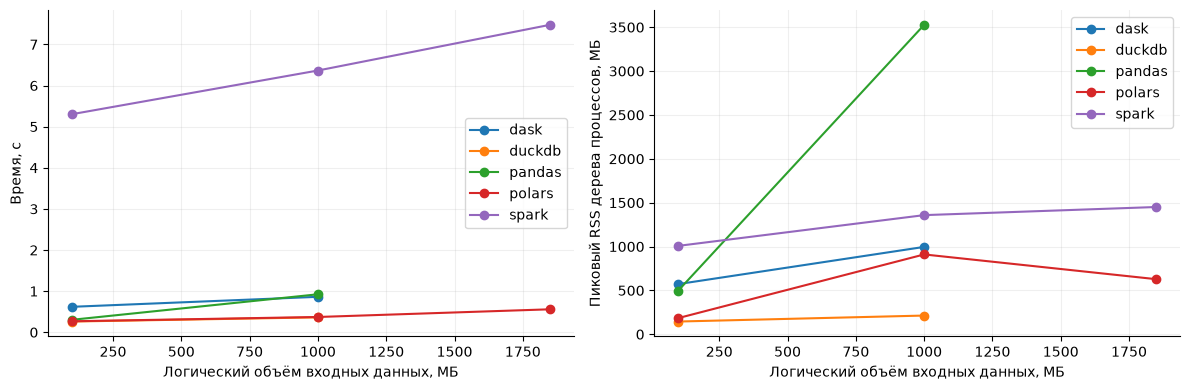

In [14]:
raw = suite(repeats=3)
table = summary(raw)
display(table)
scaling(table)

In [15]:
small = table.query("size == '1gb' and variant == 'baseline'").set_index('engine')
pandas_s = small.loc['pandas', 'seconds']
dask_s = small.loc['dask', 'seconds']
fastest = small.seconds.idxmin()
print(f'Pandas, 1 ГБ: {pandas_s:.3f} с')
print(f'Dask, 1 ГБ: {dask_s:.3f} с')
print(f'Сокращение времени Dask относительно Pandas: {(1-dask_s/pandas_s)*100:.1f} %')
print(f'Минимальное время на 1 ГБ: {fastest}, {small.loc[fastest, "seconds"]:.3f} с')
print(f'Spark, 1 ГБ: {small.loc["spark", "seconds"]:.3f} с')

Pandas, 1 ГБ: 0.924 с
Dask, 1 ГБ: 0.862 с
Сокращение времени Dask относительно Pandas: 6.7 %
Минимальное время на 1 ГБ: duckdb, 0.363 с
Spark, 1 ГБ: 6.365 с


**Вывод:** на 1 ГБ Pandas выполнил задачу за 0,924 с, Dask — за 0,862 с:
сокращение времени составило 6,7 %. DuckDB показал минимум — 0,363 с.
Spark на том же срезе потребовал 6,365 с: для короткой локальной агрегации запуск JVM
и планирование дороже выигрыша от параллелизма. Полную историю сравниваем отдельно,
а не напрямую со срезом Pandas.

Pandas справился с 1 ГБ, но его пиковый RSS достиг 3527 МБ. Экспериментальная граница
работоспособности не установлена: более крупный вход блокируется до чтения.
Экстраполировать время или OOM на 50–100 ГБ по двум точкам нельзя.
Измерения относятся к этой машине, задаче и состоянию файлового кэша;
группировка с небольшим выходом благоприятна для частичной агрегации.

## Часть 3: Анализ физического плана выполнения в Spark

План снимается с **result**, до и после action, а не только с исходного df.
Реальные stages и объёмы берём из TaskEnd в event log. Stage ID не равен позиции узла в плане;
служебное чтение схемы тоже может создать job. Сумма длительностей задач — task-time, не wall-clock stage.

In [16]:
def stages(label):
    """Реальные TaskEnd, не оценка числа stages по числу Exchange в плане."""
    import pandas as pd

    rows = []
    logs = [p for p in (ARTIFACTS / "events" / label).rglob("*")
            if p.is_file() and p.name.startswith("events_")]
    # Spark 4: events_* содержат JSON; appstatus_* — служебные файлы.
    for path in sorted(logs):
        with path.open() as stream:
            for line in stream:
                event = json.loads(line)
                if event["Event"] != "SparkListenerTaskEnd":
                    continue
                metrics = event.get("Task Metrics", {})
                read = metrics.get("Shuffle Read Metrics", {})
                write = metrics.get("Shuffle Write Metrics", {})
                rows.append(dict(stage=event["Stage ID"], task=event["Task Info"]["Index"],
                    duration_ms=event["Task Info"]["Finish Time"]-event["Task Info"]["Launch Time"],
                    input_bytes=metrics.get("Input Metrics", {}).get("Bytes Read", 0),
                    shuffle_read=read.get("Remote Bytes Read", 0)+read.get("Local Bytes Read", 0),
                    shuffle_write=write.get("Shuffle Bytes Written", 0),
                    spill_bytes=metrics.get("Disk Bytes Spilled", 0)))
    if not rows:
        raise ValueError(f"Нет TaskEnd в журналах Spark: {label}")
    return pd.DataFrame(rows)

In [17]:
label = 'spark-full-baseline-0'
print((ARTIFACTS / f'plan-{label}.txt').read_text())
tasks = stages(label)
stage_table = tasks.groupby('stage').agg(tasks=('task', 'count'),
    task_time_ms=('duration_ms', 'sum'), max_task_ms=('duration_ms', 'max'),
    median_task_ms=('duration_ms', 'median'), input_bytes=('input_bytes', 'sum'),
    shuffle_read=('shuffle_read', 'sum'), shuffle_write=('shuffle_write', 'sum'), spill_bytes=('spill_bytes', 'sum'))
display(stage_table)
print('Завершённых stages с TaskEnd:', len(stage_table))
display(json.loads((ARTIFACTS / f'config-{label}.json').read_text()))

== Physical Plan ==
* HashAggregate (5)
+- Exchange (4)
   +- * HashAggregate (3)
      +- * ColumnarToRow (2)
         +- Scan parquet  (1)


(1) Scan parquet 
Output [5]: [cell_lat#0L, cell_lon#1L, hour#2L, fare_amount#3, trip_distance#4]
Batched: true
Location: InMemoryFileIndex [file:/Users/whyalive/WORK/Магистратура 2 курс/bigdata/bigdata-engine-benchmark/data/full/yellow_tripdata_2015-01.parquet, ... 3 entries]
ReadSchema: struct<cell_lat:bigint,cell_lon:bigint,hour:bigint,fare_amount:double,trip_distance:double>

(2) ColumnarToRow [codegen id : 1]
Input [5]: [cell_lat#0L, cell_lon#1L, hour#2L, fare_amount#3, trip_distance#4]

(3) HashAggregate [codegen id : 1]
Input [5]: [cell_lat#0L, cell_lon#1L, hour#2L, fare_amount#3, trip_distance#4]
Keys [3]: [cell_lat#0L, cell_lon#1L, hour#2L]
Functions [3]: [partial_count(1), partial_avg(fare_amount#3), partial_sum(trip_distance#4)]
Aggregate Attributes [4]: [count#17L, sum#18, count#19L, sum#20]
Results [7]: [cell_lat#0L, cell_lon#1L, ho

,tasks,task_time_ms,max_task_ms,median_task_ms,input_bytes,shuffle_read,shuffle_write,spill_bytes
stage,,,,,,,,
0,1,127,127,127.0,0,0,0,0
1,49,8794,842,120.0,1082371,0,9208053,0
2,200,1906,43,8.0,0,9208053,0,0


Завершённых stages с TaskEnd: 3


{'spark.driver.host': 'localhost',
 'spark.sql.artifact.isolation.enabled': 'false',
 'spark.app.name': 'spark-full-baseline-0',
 'spark.eventLog.dir': 'file:///var/folders/kz/sc6g4vys1bq6x8t4ww7jnqjw0000gn/T/taxi-benchmark-fcqp50r0/events/spark-full-baseline-0',
 'spark.sql.warehouse.dir': 'file:/Users/whyalive/WORK/Магистратура%202%20курс/bigdata/bigdata-engine-benchmark/spark-warehouse',
 'spark.executor.id': 'driver',
 'spark.ui.enabled': 'false',
 'spark.sql.session.timeZone': 'UTC',
 'spark.default.parallelism': '200',
 'spark.submit.deployMode': 'client',
 'spark.eventLog.compress': 'false',
 'spark.serializer.objectStreamReset': '100',
 'spark.app.submitTime': '1794408939425',
 'spark.app.startTime': '1794408939531',
 'spark.ui.showConsoleProgress': 'true',
 'spark.sql.shuffle.partitions': '200',
 'spark.app.id': 'local-1794408940121',
 'spark.executor.extraJavaOptions': '-Djava.net.preferIPv6Addresses=false -XX:+IgnoreUnrecognizedVMOptions --add-modules=jdk.incubator.vector --

**Разбор:** в event log baseline зафиксированы три завершённых stage:

- Stage 0: одна служебная задача, 127 мс task-time, shuffle отсутствует.
- Stage 1: 49 задач, чтение пяти колонок Parquet, `ColumnarToRow` и локальный
  `HashAggregate` с частичными суммами и счётчиками; 8794 мс суммарного task-time.
  Счётчик input bytes сообщил 1 082 371 байт — это значение Spark, не размер всего Parquet.
- Stage 2: 200 задач, получение частичных агрегатов через
  `Exchange hashpartitioning(cell_lat, cell_lon, hour, 200)` и финальный `HashAggregate`;
  1906 мс task-time. Shuffle write/read составил 9 208 053 байта, spill — 0.

Среднее вычисляется через сумму и количество. Суммарный task-time не равен времени
stage по часам: задачи выполняются параллельно. Самый дорогой по сумме task-time этап —
чтение и частичная агрегация; самая долгая его задача заняла 842 мс при медиане 120 мс.
Эти различия сами по себе не доказывают skew reduce-задач.

**Гипотезы об оптимизации:** 200 маленьких reduce-задач на четырёх ядрах создают
накладные расходы планировщика; 12 партиций и объединение мелких разделов через AQE
могут быть дешевле. Repartition до агрегации рискует ухудшить план: вместо компактных
partial aggregates передаются исходные строки. В baseline AQE отключён;
его эффект проверяем отдельным вариантом.

## Часть 4: Выявление и устранение skew

Проверяем **полный составной ключ**, используемый в задаче, а не только широту.
CV = std/mean (population std), отдельно показываем variance/mean и max/mean.
Универсального порога CV нет: редкие ключи и суточный профиль естественно повышают разброс.
Salting — контролируемый эксперимент даже если baseline уже справляется с дисбалансом.
16 солей, затем повторная агрегация; средний тариф восстанавливаем как SUM(fare_sum)/SUM(count).

In [18]:
def skew():
    distribution = (pl.scan_parquet(DATA / "full/*.parquet").group_by(KEYS)
                    .len().sort("len", descending=True).collect())
    counts = distribution["len"].to_numpy()
    top = distribution.head(20).to_pandas()
    top["key"] = top[KEYS].astype(str).agg("/".join, axis=1)
    top.plot.bar(x="key", y="len", legend=False, figsize=(12, 4))
    plt.ylabel("Поездок")
    plt.title("20 наиболее частых полных ключей: ячейка × час суток")
    plt.tight_layout()
    plt.show()
    return pd.Series(dict(keys=len(counts), cv=np.std(counts)/np.mean(counts),
                          variance_to_mean=np.var(counts)/np.mean(counts),
                          max_to_mean=np.max(counts)/np.mean(counts),
                          top1_share=counts[0]/counts.sum()))

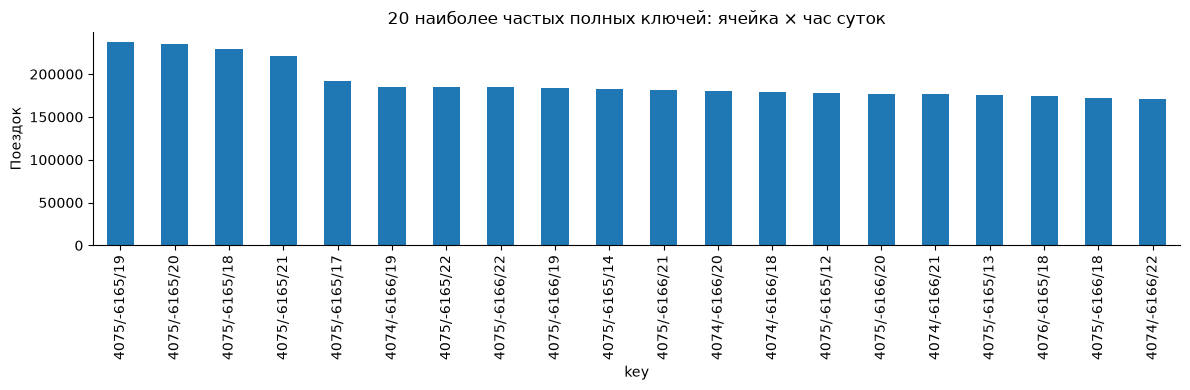

keys                16416.000000
cv                      5.276625
variance_to_mean    78403.469391
max_to_mean            84.132227
top1_share              0.005125
dtype: float64

,engine,size,variant,seconds,min_s,max_s,peak_rss_mb,cpu_percent,read_bytes,write_bytes,read_ops,write_ops
12,spark,full,baseline,7.475966,6.863597,7.915072,1450.541056,345.614993,0.0,51900416.0,NaN,NaN
16,spark,full,salt,10.301222,10.270570,10.776212,1580.859392,411.976151,0.0,296767488.0,NaN,NaN


,max_ms,median_ms,shuffle_write,spill_bytes
stage,,,,
0,127,127.0,0,0
1,842,120.0,9208053,0
2,43,8.0,0,0


,max_ms,median_ms,shuffle_write,spill_bytes
stage,,,,
0,120,120.0,0,0
1,677,149.0,50713230,0
2,131,53.0,5719713,0
3,28,12.0,0,0


== Physical Plan ==
* HashAggregate (9)
+- Exchange (8)
   +- * HashAggregate (7)
      +- * HashAggregate (6)
         +- Exchange (5)
            +- * HashAggregate (4)
               +- * Project (3)
                  +- * ColumnarToRow (2)
                     +- Scan parquet  (1)


(1) Scan parquet 
Output [5]: [cell_lat#0L, cell_lon#1L, hour#2L, fare_amount#3, trip_distance#4]
Batched: true
Location: InMemoryFileIndex [file:/Users/whyalive/WORK/Магистратура 2 курс/bigdata/bigdata-engine-benchmark/data/full/yellow_tripdata_2015-01.parquet, ... 3 entries]
ReadSchema: struct<cell_lat:bigint,cell_lon:bigint,hour:bigint,fare_amount:double,trip_distance:double>

(2) ColumnarToRow [codegen id : 1]
Input [5]: [cell_lat#0L, cell_lon#1L, hour#2L, fare_amount#3, trip_distance#4]

(3) Project [codegen id : 1]
Output [6]: [cell_lat#0L, cell_lon#1L, hour#2L, fare_amount#3, trip_distance#4, cast((rand(42) * 16.0) as int) AS salt#6]
Input [5]: [cell_lat#0L, cell_lon#1L, hour#2L, fare_amount#3, t

In [19]:
skew_metrics = skew()
display(skew_metrics)
display(table.query("engine == 'spark' and size == 'full' and variant in ['baseline', 'salt']"))
for variant in ['baseline', 'salt']:
    t = stages(f'spark-full-{variant}-0')
    display(t.groupby('stage').agg(max_ms=('duration_ms', 'max'), median_ms=('duration_ms', 'median'),
                                 shuffle_write=('shuffle_write', 'sum'), spill_bytes=('spill_bytes', 'sum')))
print((ARTIFACTS / 'plan-spark-full-salt-0.txt').read_text())
base = table.query("engine == 'spark' and size == 'full'").set_index('variant')
print(f'Spark baseline: {base.loc["baseline", "seconds"]:.3f} с')
print(f'Spark salting: {base.loc["salt", "seconds"]:.3f} с')
print(f'Ускорение salting: {base.loc["baseline", "seconds"]/base.loc["salt", "seconds"]:.2f}×')

**Вывод:** для 16 416 составных ключей CV = 5,28, variance/mean = 78 403,47,
максимальная частота в 84,13 раза выше средней. Самый популярный ключ содержит 0,51 % поездок.
Распределение неравномерно, но baseline уже уменьшает поток с помощью map-side combine.

Salting сохранил результат, однако увеличил медиану с 7,476 до 10,301 с
(ускорение 0,73×, то есть замедление на 37,8 %). Вместо одного Exchange появились два;
суммарный shuffle write в первом повторе вырос с 9,21 до 56,43 МБ, spill остался нулевым.
Поэтому для этой агрегации salting не выбираем: дополнительная агрегация и shuffle дороже
выигрыша от распределения горячих ключей. Сами горячие ключи не удаляем — это потеря спроса.

## Часть 5: Оптимизация Spark-кода

Три независимых изменения к одному baseline: **200 → 12 shuffle-партиций**,
**AQE off → on**, **repartition по ключу перед groupBy**. Дополнительно salting и комбинация 12+AQE.
Во всех случаях одинаковые входные Parquet и действие collect; кэширование не используется.
`default.parallelism` меняется вместе с числом партиций; для этого DataFrame-shuffle определяющим является SQL-параметр.
Parquet уже общий формат: его преимущество над CSV здесь не приписываем другим оптимизациям.

In [20]:
def optimization(table):
    result = table.query("engine == 'spark' and size == 'full'").copy()
    baseline = result.query("variant == 'baseline'").iloc[0]
    result["speedup"] = baseline.seconds/result.seconds
    result["saved_percent"] = (1-result.seconds/baseline.seconds)*100
    result["extra_rss_mb"] = result.peak_rss_mb-baseline.peak_rss_mb
    result.plot.scatter(x="extra_rss_mb", y="saved_percent", figsize=(9, 4))
    for _, row in result.iterrows():
        plt.annotate(row.variant, (row.extra_rss_mb, row.saved_percent))
    plt.axhline(0, color="gray", linestyle="--")
    plt.xlabel("Дополнительный пиковый RSS относительно baseline, МБ")
    plt.ylabel("Сокращение времени, % (отрицательное = ухудшение)")
    plt.title("Затраты RAM vs. выгода по времени")
    plt.tight_layout()
    plt.show()
    return result[["variant", "seconds", "min_s", "max_s", "peak_rss_mb", "speedup", "saved_percent"]]

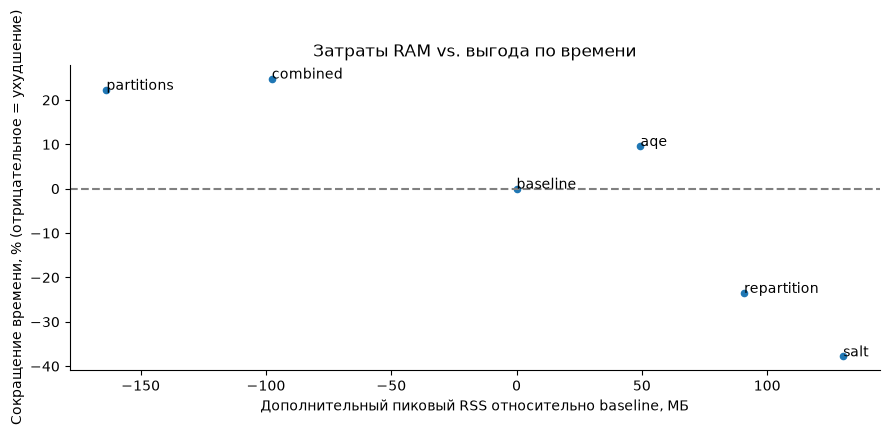

,variant,seconds,min_s,max_s,peak_rss_mb,speedup,saved_percent
11,aqe,6.756892,6.728126,6.790344,1499.971584,1.106421,9.618470
12,baseline,7.475966,6.863597,7.915072,1450.541056,1.000000,0.000000
13,combined,5.621513,5.603429,5.630895,1352.908800,1.329885,24.805536
14,partitions,5.810192,5.775536,6.295000,1286.914048,1.286699,22.281729
15,repartition,9.232165,9.211796,9.242236,1541.324800,0.809774,-23.491271
16,salt,10.301222,10.270570,10.776212,1580.859392,0.725736,-37.791182


Лучшая проверенная конфигурация: combined
Время: 5.622 с; ускорение: 1.33×


In [21]:
opt = optimization(table)
display(opt)
best = opt.loc[opt.seconds.idxmin()]
print(f'Лучшая проверенная конфигурация: {best.variant}')
print(f'Время: {best.seconds:.3f} с; ускорение: {best.speedup:.2f}×')

**Вывод:** уменьшение числа shuffle-партиций до 12 сократило время на 22,3 %,
включение AQE отдельно — на 9,6 %. Repartition увеличил время на 23,5 %,
salting — на 37,8 %: дополнительный shuffle здесь не окупился.

Лучшая проверенная конфигурация — **12 партиций + AQE**: 5,622 с против 7,476 с baseline,
ускорение 1,33×, сокращение времени на 24,8 %. Её пиковый RSS — 1352,9 МБ
против 1450,5 МБ baseline. Для данного локального задания выбираем эту комбинацию;
это не глобальный оптимум всех параметров. Отрицательный эффект также является результатом,
а график RAM/выгоды не измеряет трудоёмкость разработки.

## Часть 6: GPU vs CPU

### Трек A (по умолчанию, локально на CPU): Polars/DuckDB против pandas

На macOS без NVIDIA сравниваем CPU-реализации. Логика агрегации одинакова во всех реализациях.
Polars использует lazy/streaming, Arrow и многопоточность, DuckDB — векторизованный SQL;
Pandas — векторизованные операции, а не Python-цикл. Некоторые операции Pandas и I/O тоже могут использовать потоки:
не трактуем сравнение как строго «один поток против четырёх».

In [22]:
def cpu_track(table):
    part = table.query("engine in ['pandas', 'polars', 'duckdb'] and variant == 'baseline'").copy()
    baseline = part.query("engine == 'pandas'")[["size", "seconds"]].rename(columns={"seconds": "pandas_s"})
    part = part.merge(baseline, on="size")
    part["saved_percent"] = (1-part.seconds/part.pandas_s)*100
    return part[["engine", "size", "seconds", "peak_rss_mb", "saved_percent"]]

In [23]:
cpu = cpu_track(table)
display(cpu)
display(cpu.pivot(index='engine', columns='size', values=['seconds', 'peak_rss_mb']))
for row in cpu.query("size == '1gb'").itertuples():
    print(f'{row.engine}, 1 ГБ: {row.seconds:.3f} с; RSS {row.peak_rss_mb:.1f} МБ; сокращение времени {row.saved_percent:.1f} %')

,engine,size,seconds,peak_rss_mb,saved_percent
0,duckdb,100mb,0.261158,145.195008,13.969890
1,duckdb,1gb,0.362643,213.319680,60.743955
2,pandas,100mb,0.303566,498.089984,0.000000
3,pandas,1gb,0.923790,3527.049216,0.000000
4,polars,100mb,0.267592,184.582144,11.850305
5,polars,1gb,0.371807,910.000128,59.751959


seconds           peak_rss_mb             
size       100mb       1gb       100mb          1gb
engine                                             
duckdb  0.261158  0.362643  145.195008   213.319680
pandas  0.303566  0.923790  498.089984  3527.049216
polars  0.267592  0.371807  184.582144   910.000128

duckdb, 1 ГБ: 0.363 с; RSS 213.3 МБ; сокращение времени 60.7 %
pandas, 1 ГБ: 0.924 с; RSS 3527.0 МБ; сокращение времени 0.0 %
polars, 1 ГБ: 0.372 с; RSS 910.0 МБ; сокращение времени 59.8 %


**Вывод:** на 1 ГБ Polars сократил время относительно Pandas на 59,8 %
(0,372 против 0,924 с), DuckDB — на 60,7 % (0,363 с).
Пиковый RSS составил соответственно 910,0 и 213,3 МБ против 3527,0 МБ у Pandas.
На 100 МБ выигрыш скромнее: 11,9 % у Polars и 14,0 % у DuckDB.
Результат согласуется с преимуществами lazy/streaming, многопоточности и векторизованного SQL;
отдельный вклад каждого механизма этим замером не изолирован.

GPU не тестировался: NVIDIA-плагин недоступен на этой macOS-машине.
CPU-результаты нельзя выдавать за GPU-ускорение. Измеренные запросы короткие,
поэтому инициализация GPU и перенос CPU↔GPU могут оказаться дороже вычислений;
примерный ориентир 30 с из задания — не измеренная здесь граница окупаемости.
RDD, GraphX и построчные Python UDF этим плагином не ускоряются.

## Часть 7: Рекомендации по выбору инструмента

### 7.1. Матрица выбора

| Условие | Pandas | Dask | Spark | Polars / DuckDB | Рекомендация |
|---|---|---|---|---|---|
| <100 МБ, интерактивный анализ | +++ | ++ | + | +++ | Простота Pandas или SQL DuckDB |
| 1 ГБ, локальная агрегация | ++ | ++ | + | +++ | Выбирать по замеру выше |
| Больше RAM, но один сервер | + | +++ | ++ | +++ | Dask / streaming Polars / DuckDB со spill |
| >50 ГБ, несколько узлов, retries | + | ++ | +++ | ++ | Spark при необходимости кластера |
| >50 ГБ, NVIDIA, тяжёлый SQL | + | ++ | +++ | ++ | Протестировать GPU-плагин, не обещать ускорение |
| <30 с, I/O-bound, нет NVIDIA | +++ | ++ | + | +++ | CPU; GPU может не окупиться |

Оценки качественные, не универсальные пороги. Распределённость и fault tolerance на нескольких узлах
не тестировались на локальной машине. Нужный инструмент определяется ещё и RAM, кардинальностью,
SLA и компетенциями команды, а не только гигабайтами.

### 7.2. Cost/performance

Сценарные, редактируемые допущения: VM 30 ₽/ч, инженер 1500 ₽/ч, 30 заданий/месяц.
Разработку амортизируем на 12 месяцев; трудозатраты — **оценки**, не замеры и не рыночные тарифы.
Для сопоставимости берём 1 ГБ для всех движков. Вычисления = seconds/3600 × VM price;
месячный TCO = compute × jobs + support × salary + dev × salary/12.
Запуск VM, минимальный биллинг и хранение здесь не учтены; для собственного ноутбука предельная цена VM = 0.

In [24]:
def economics(table, vm_rub_hour=30, engineer_rub_hour=1500, jobs_month=30):
    # Это сценарные допущения, не измеренное время разработки и не облачный тариф.
    estimates = {"pandas": (4, 1), "dask": (8, 2), "spark": (16, 4), "polars": (6, 1), "duckdb": (6, 1)}
    part = table.query("size == '1gb' and variant == 'baseline'").copy()
    part["dev_hours_assumed"] = part.engine.map(lambda e: estimates[e][0])
    part["support_hours_month_assumed"] = part.engine.map(lambda e: estimates[e][1])
    part["compute_rub_job"] = part.seconds/3600*vm_rub_hour
    part["tco_rub_month"] = (part.compute_rub_job*jobs_month
        + part.support_hours_month_assumed*engineer_rub_hour
        + part.dev_hours_assumed*engineer_rub_hour/12)
    part["rub_per_gb_job"] = part.compute_rub_job
    return part[["engine", "seconds", "compute_rub_job", "dev_hours_assumed",
                 "support_hours_month_assumed", "tco_rub_month", "rub_per_gb_job"]]

In [25]:
display(economics(table))
for rate in [0, 30, 100]:
    print(f'Чувствительность к цене VM {rate} ₽/ч')
    display(economics(table, vm_rub_hour=rate)[['engine', 'compute_rub_job', 'tco_rub_month']])

,engine,seconds,compute_rub_job,dev_hours_assumed,support_hours_month_assumed,tco_rub_month,rub_per_gb_job
1,dask,0.862245,0.007185,8,2,4000.215561,0.007185
3,duckdb,0.362643,0.003022,6,1,2250.090661,0.003022
5,pandas,0.923790,0.007698,4,1,2000.230947,0.007698
7,polars,0.371807,0.003098,6,1,2250.092952,0.003098
10,spark,6.365345,0.053045,16,4,8001.591336,0.053045


Чувствительность к цене VM 0 ₽/ч


,engine,compute_rub_job,tco_rub_month
1,dask,0.0,4000.0
3,duckdb,0.0,2250.0
5,pandas,0.0,2000.0
7,polars,0.0,2250.0
10,spark,0.0,8000.0


Чувствительность к цене VM 30 ₽/ч


,engine,compute_rub_job,tco_rub_month
1,dask,0.007185,4000.215561
3,duckdb,0.003022,2250.090661
5,pandas,0.007698,2000.230947
7,polars,0.003098,2250.092952
10,spark,0.053045,8001.591336


Чувствительность к цене VM 100 ₽/ч


,engine,compute_rub_job,tco_rub_month
1,dask,0.023951,4000.718537
3,duckdb,0.010073,2250.302203
5,pandas,0.025661,2000.769825
7,polars,0.010328,2250.309839
10,spark,0.176815,8005.304454


### 7.3. Бизнес-сценарий и компромиссы

Для почасового профиля спроса на одном узле предпочтителен Polars или DuckDB, если их замеры укладываются
в SLA и память. Polars проще встроить в Python-пайплайн, DuckDB удобен SQL-команде.
Pandas оставляем для исследования компактных срезов; Dask — когда важна совместимость с Pandas
и обработка по разделам. Spark оправдан при росте до нескольких узлов, требованиях к восстановлению
и интеграции с lakehouse; локальный запуск не демонстрирует этих преимуществ.

Окно до 06:00 — 21 600 секунд. Сопоставляем с ним полный Spark/Polars-замер ниже;
это только подготовка профиля, не обучение прогноза. Цель -25 % холостых часов по этим бенчмаркам
не доказана — её проверяют A/B-пилотом.

In [26]:
full = table.query("size == 'full' and variant == 'baseline'").copy()
full['sla_used_percent'] = full.seconds/21600*100
display(full[['engine', 'seconds', 'peak_rss_mb', 'sla_used_percent']])

,engine,seconds,peak_rss_mb,sla_used_percent
8,polars,0.558660,628.162560,0.002586
12,spark,7.475966,1450.541056,0.034611


**Вывод:** полный профиль Polars подготовил за 0,559 с при пиковом RSS 628,2 МБ,
Spark baseline — за 7,476 с при 1450,5 МБ. Это 0,0026 % и 0,0346 % шестичасового окна;
оба варианта укладываются в него, но обучение прогноза в замер не входит.
Для локального Python-пайплайна выбираем Polars; для SQL-команды DuckDB —
сильная альтернатива по сравнению на 1 ГБ, но полный набор им здесь не измерялся.

При заданных допущениях месячный TCO на сопоставимом срезе составляет около 2000 ₽ для Pandas,
2250 ₽ для Polars/DuckDB, 4000 ₽ для Dask и 8002 ₽ для Spark.
Это сценарная оценка, а не фактические расходы: разработка и поддержка доминируют
над вычислениями. Если Pandas уже удовлетворяет SLA и памяти, переход ради долей секунды
может быть невыгоден. При выборе Polars принимаем стоимость освоения API и отсутствие
проверенной здесь многоузловой отказоустойчивости; Spark оставляем для требований к кластеру.

Риски: рост кардинальности и RAM, изменение схемы TLC, нерепрезентативные временные срезы,
конкурирующая нагрузка на ноутбуке, вариативность файлового кэша. Нужны повторные замеры
на production-подобных объёмах, SLA-мониторинг и валидация каждой новой партии.
Снижение холостых часов на 25 % этими замерами не доказано: нужен A/B-пилот.

## Заключение

1. Одна задача реализована пятью движками; результаты всех 51 замера автоматически сверены.
2. На 1 ГБ Dask сократил время относительно Pandas на 6,7 %, Polars — на 59,8 %, DuckDB — на 60,7 %.
3. План Spark содержит частичную агрегацию, Exchange и финальное объединение;
   baseline передал 9,21 МБ shuffle без spill в разобранном повторе.
4. Для Spark выбрана комбинация 12 партиций + AQE (1,33×); salting и repartition замедлили задачу.
5. Для локальной подготовки профиля выбран Polars. GPU не измерялся;
   решение о дальнейшем усложнении стека зависит от памяти, SLA, TCO и требований к отказоустойчивости.

In [27]:
workspace.cleanup()  # Удаляем временные результаты замеров и event logs.